# IDS project: training and evaluation

Models
- **RF**: Random Forest baseline, trained on our Mininet data only.
- **Model A**: MLP neural network trained **from scratch** on our Mininet data only.
- **Model P**: the same MLP **pre-trained** on CIC-IDS2017 only (step 1 of Model B).
- **Model B**: Model P **fine-tuned** on our Mininet data with a 10x lower learning rate.

Inputs (put them next to this notebook)
- `dataset/flows.csv`, made on Kali by `extract_flows.py`
- `cic/`, the CIC-IDS2017 *MachineLearningCSV* files (Monday, Tuesday, Wednesday, Friday-Afternoon-PortScan)

Outputs
- `results/`: tables and charts for the report (black and white)
- `models/detector.npz`: the best MLP, copied back to Kali for `live_detector.py`

Install if needed: `pip install torch pandas scikit-learn matplotlib`

In [12]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [13]:
import os, copy, glob, time
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

MININET_CSV = "dataset/flows.csv"   # from Kali
CIC_DIR = "cic"                     # CIC-IDS2017 MachineLearningCSV files
CIC_CACHE = "dataset/cic.csv"       # made by this notebook (reused if it exists)
CIC_PER_CLASS = 20000               # max CIC rows per class
SEEDS = [0, 1, 2]

os.makedirs("results_2", exist_ok=True); os.makedirs("models", exist_ok=True); os.makedirs("dataset", exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
plt.rcParams.update({"font.size": 9})

CLASSES = ["benign", "http_flood", "port_scan", "slow_dos", "ssh_brute"]
CIDX = {c: i for i, c in enumerate(CLASSES)}

Device: cpu 


## 1. Features

Same 50 flow features as `flowfeat.py` on Kali, with the CIC-IDS2017 definitions:
times in microseconds, packet length = payload bytes, sample standard deviation.
Identifiers (IPs, ports, protocol, timestamp) are **not** model inputs.

In [14]:
FEATURES = [
    "flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "totlen_fwd_pkts", "totlen_bwd_pkts",
    "fwd_pkt_len_max", "fwd_pkt_len_min", "fwd_pkt_len_mean", "fwd_pkt_len_std",
    "bwd_pkt_len_max", "bwd_pkt_len_min", "bwd_pkt_len_mean", "bwd_pkt_len_std",
    "flow_byts_s", "flow_pkts_s",
    "flow_iat_mean", "flow_iat_std", "flow_iat_max", "flow_iat_min",
    "fwd_iat_tot", "fwd_iat_mean", "fwd_iat_std", "fwd_iat_max", "fwd_iat_min",
    "bwd_iat_tot", "bwd_iat_mean", "bwd_iat_std", "bwd_iat_max", "bwd_iat_min",
    "fwd_psh_flags", "fwd_pkts_s", "bwd_pkts_s",
    "pkt_len_min", "pkt_len_max", "pkt_len_mean", "pkt_len_std", "pkt_len_var",
    "fin_flag_cnt", "syn_flag_cnt", "rst_flag_cnt", "psh_flag_cnt", "ack_flag_cnt",
    "urg_flag_cnt", "down_up_ratio", "pkt_size_avg", "fwd_seg_size_avg", "bwd_seg_size_avg",
    "init_fwd_win_byts", "init_bwd_win_byts", "fwd_act_data_pkts",
]

def transform(X):
    """inf/NaN -> 0, then signed log: shrinks huge ranges (bytes/s, microseconds)."""
    X = np.nan_to_num(np.asarray(X, dtype=float), nan=0.0, posinf=0.0, neginf=0.0)
    return np.sign(X) * np.log1p(np.abs(X))

# CIC-IDS2017 column (spaces stripped) -> our feature name
CIC_COLS = {
    "Flow Duration": "flow_duration", "Total Fwd Packets": "tot_fwd_pkts",
    "Total Backward Packets": "tot_bwd_pkts", "Total Length of Fwd Packets": "totlen_fwd_pkts",
    "Total Length of Bwd Packets": "totlen_bwd_pkts",
    "Fwd Packet Length Max": "fwd_pkt_len_max", "Fwd Packet Length Min": "fwd_pkt_len_min",
    "Fwd Packet Length Mean": "fwd_pkt_len_mean", "Fwd Packet Length Std": "fwd_pkt_len_std",
    "Bwd Packet Length Max": "bwd_pkt_len_max", "Bwd Packet Length Min": "bwd_pkt_len_min",
    "Bwd Packet Length Mean": "bwd_pkt_len_mean", "Bwd Packet Length Std": "bwd_pkt_len_std",
    "Flow Bytes/s": "flow_byts_s", "Flow Packets/s": "flow_pkts_s",
    "Flow IAT Mean": "flow_iat_mean", "Flow IAT Std": "flow_iat_std",
    "Flow IAT Max": "flow_iat_max", "Flow IAT Min": "flow_iat_min",
    "Fwd IAT Total": "fwd_iat_tot", "Fwd IAT Mean": "fwd_iat_mean", "Fwd IAT Std": "fwd_iat_std",
    "Fwd IAT Max": "fwd_iat_max", "Fwd IAT Min": "fwd_iat_min",
    "Bwd IAT Total": "bwd_iat_tot", "Bwd IAT Mean": "bwd_iat_mean", "Bwd IAT Std": "bwd_iat_std",
    "Bwd IAT Max": "bwd_iat_max", "Bwd IAT Min": "bwd_iat_min",
    "Fwd PSH Flags": "fwd_psh_flags", "Fwd Packets/s": "fwd_pkts_s", "Bwd Packets/s": "bwd_pkts_s",
    "Min Packet Length": "pkt_len_min", "Max Packet Length": "pkt_len_max",
    "Packet Length Mean": "pkt_len_mean", "Packet Length Std": "pkt_len_std",
    "Packet Length Variance": "pkt_len_var",
    "FIN Flag Count": "fin_flag_cnt", "SYN Flag Count": "syn_flag_cnt",
    "RST Flag Count": "rst_flag_cnt", "PSH Flag Count": "psh_flag_cnt",
    "ACK Flag Count": "ack_flag_cnt", "URG Flag Count": "urg_flag_cnt",
    "Down/Up Ratio": "down_up_ratio", "Average Packet Size": "pkt_size_avg",
    "Avg Fwd Segment Size": "fwd_seg_size_avg", "Avg Bwd Segment Size": "bwd_seg_size_avg",
    "Init_Win_bytes_forward": "init_fwd_win_byts", "Init_Win_bytes_backward": "init_bwd_win_byts",
    "act_data_pkt_fwd": "fwd_act_data_pkts",
}
CIC_LABELS = {"BENIGN": "benign", "DoS Hulk": "http_flood", "DoS slowloris": "slow_dos",
              "DoS Slowhttptest": "slow_dos", "PortScan": "port_scan", "SSH-Patator": "ssh_brute"}
assert sorted(CIC_COLS.values()) == sorted(FEATURES)

## 2. Our Mininet dataset

In [15]:
mn = pd.read_csv(MININET_CSV)
mn = mn[mn.label.isin(CLASSES)]
print(len(mn), "flows")
mn.groupby(["label", "split_group"]).size().unstack(fill_value=0)

60464 flows


split_group,heldout,main
label,,
benign,1752,7166
http_flood,1413,15218
port_scan,5248,26415
slow_dos,320,2501
ssh_brute,101,330


## 3. CIC-IDS2017 (external data)

Only the 5 matching labels are kept: BENIGN, DoS Hulk, DoS slowloris + DoS Slowhttptest
(both = slow_dos), PortScan, SSH-Patator. Up to `CIC_PER_CLASS` rows per class.

In [16]:
if os.path.exists(CIC_CACHE):
    cic = pd.read_csv(CIC_CACHE)
    print("Loaded", CIC_CACHE)
else:
    parts = []
    for path in sorted(glob.glob(os.path.join(CIC_DIR, "*.csv"))):
        df = pd.read_csv(path, encoding="latin-1", low_memory=False)
        df.columns = [c.strip() for c in df.columns]
        if "Label" not in df.columns or any(c not in df.columns for c in CIC_COLS):
            print("skip (columns differ):", os.path.basename(path)); continue
        lab = df["Label"].astype(str).str.strip()
        df = df[lab.isin(CIC_LABELS)]
        if df.empty:
            continue
        out = df[list(CIC_COLS)].rename(columns=CIC_COLS)
        out["label"] = df["Label"].astype(str).str.strip().map(CIC_LABELS).values
        out["source_file"] = os.path.basename(path)
        parts.append(out)
        print(os.path.basename(path), out.label.value_counts().to_dict())
    cic = pd.concat(parts, ignore_index=True)
    cic = pd.concat([g.sample(min(len(g), CIC_PER_CLASS), random_state=0)
                     for _, g in cic.groupby("label")], ignore_index=True)
    cic.to_csv(CIC_CACHE, index=False)
cic.label.value_counts()

Loaded dataset/cic.csv


label
benign        20000
http_flood    20000
port_scan     20000
slow_dos      11295
ssh_brute      5897
Name: count, dtype: int64

## 4. Splits and preprocessing

| Set | Used for |
|---|---|
| Mininet main runs (S001-S003), 85% | training RF, Model A, fine-tuning Model B |
| Mininet main runs, 15% | validation (early stopping only) |
| Mininet held-out run S004 (tree topology) | **test**: new network layout |
| CIC-IDS2017, 70% | pre-training Model P / B only |
| CIC-IDS2017, 30% | **test**: different network, never trained on by any model |

Features that never change in the Mininet training data are dropped.
Each model's scaler is fit on its own training data only.

In [17]:
main, mtest = mn[mn.split_group == "main"], mn[mn.split_group == "heldout"]
feats = [f for f in FEATURES if main[f].nunique() > 1]
print(f"{len(feats)} features used; dropped (constant): {[f for f in FEATURES if f not in feats]}")

Xf = lambda df: transform(df[feats].values)
yf = lambda df: df.label.map(CIDX).values
cic_tr, cic_te = train_test_split(cic, test_size=0.3, stratify=cic.label, random_state=0)
TESTS = {"mininet_test": (Xf(mtest), yf(mtest)), "cic_test": (Xf(cic_te), yf(cic_te))}
print({k: len(v[1]) for k, v in TESTS.items()})

50 features used; dropped (constant): []
{'mininet_test': 8834, 'cic_test': 23158}


## 5. Models

MLP: 128 -> 64 hidden units (ReLU, dropout 0.1), Adam, cross-entropy.
Each epoch draws a **class-balanced** sample (4,000 rows per class), so small classes
(ssh_brute, slow_dos) count as much as port_scan. Early stopping on validation macro-F1
(patience 8). Fine-tuning keeps the pre-trained weights and uses learning rate 1e-4 instead of 1e-3.

In [18]:
class MLP(nn.Module):
    def __init__(self, n_in, n_out=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(64, n_out))
    def forward(self, x):
        return self.net(x)


def predict(model, X, bs=8192):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = torch.tensor(X[i:i + bs], dtype=torch.float32, device=DEVICE)
            out.append(model(xb).argmax(1).cpu().numpy())
    return np.concatenate(out)


def train_mlp(Xtr, ytr, Xva, yva, seed, init=None, lr=1e-3, epochs=60, patience=8,
              per_class=4000, bs=512):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = (copy.deepcopy(init) if init is not None else MLP(Xtr.shape[1])).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    lossf = nn.CrossEntropyLoss()
    Xt = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(ytr, dtype=torch.long, device=DEVICE)
    best, best_f1, bad, hist = None, -1, 0, []
    for ep in range(epochs):
        idx = np.concatenate([rng.choice(np.where(ytr == c)[0], per_class, replace=True)
                              for c in range(len(CLASSES)) if (ytr == c).any()])
        rng.shuffle(idx)
        idx = torch.tensor(idx, device=DEVICE)
        model.train()
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]
            opt.zero_grad()
            lossf(model(Xt[b]), yt[b]).backward()
            opt.step()
        f1 = f1_score(yva, predict(model, Xva), average="macro")
        hist.append(f1)
        if f1 > best_f1 + 1e-4:
            best, best_f1, bad = copy.deepcopy(model), f1, 0
        else:
            bad += 1
            if bad >= patience:
                break
    print(f"    {ep + 1} epochs, best val macro-F1 {best_f1:.3f}")
    return best, hist

## 6. Train and evaluate (3 seeds)

In [19]:
rows, recalls, cms, curves, keep = [], [], {}, {}, {}

def evaluate(name, predict_fn, scaler, seed):
    for tname, (Xt, yt) in TESTS.items():
        Xs = scaler.transform(Xt)
        t0 = time.perf_counter(); pred = predict_fn(Xs); us = (time.perf_counter() - t0) / len(Xs) * 1e6
        ben = yt == CIDX["benign"]
        rows.append({"model": name, "test": tname, "seed": seed,
                     "macro_f1": f1_score(yt, pred, average="macro", labels=range(len(CLASSES))),
                     "accuracy": (pred == yt).mean(),
                     "benign_fpr": (pred[ben] != CIDX["benign"]).mean(),
                     "attack_recall": (pred[~ben] != CIDX["benign"]).mean(),
                     "us_per_flow": us})
        rec = recall_score(yt, pred, labels=range(len(CLASSES)), average=None, zero_division=0)
        recalls.append({"model": name, "test": tname, "seed": seed, **dict(zip(CLASSES, rec))})
        if seed == SEEDS[0]:
            cms[(name, tname)] = confusion_matrix(yt, pred, labels=range(len(CLASSES)))

for seed in SEEDS:
    print(f"=== seed {seed}")
    tr, va = train_test_split(main, test_size=0.15, stratify=main.label, random_state=seed)
    Xtr_raw, ytr, Xva_raw, yva = Xf(tr), yf(tr), Xf(va), yf(va)
    sc_m = StandardScaler().fit(Xtr_raw)
    Xtr, Xva = sc_m.transform(Xtr_raw), sc_m.transform(Xva_raw)

    print("  RF baseline")
    rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=seed).fit(Xtr, ytr)
    evaluate("RF", rf.predict, sc_m, seed)

    print("  Model A (from scratch)")
    mA, hA = train_mlp(Xtr, ytr, Xva, yva, seed)
    evaluate("A_scratch", lambda X: predict(mA, X), sc_m, seed)

    ctr, cva = train_test_split(cic_tr, test_size=0.15, stratify=cic_tr.label, random_state=seed)
    sc_c = StandardScaler().fit(Xf(ctr))
    print("  Model P (pre-train on CIC-IDS2017)")
    mP, hP = train_mlp(sc_c.transform(Xf(ctr)), yf(ctr), sc_c.transform(Xf(cva)), yf(cva), seed)
    evaluate("P_pretrained_only", lambda X: predict(mP, X), sc_c, seed)

    print("  Model B (fine-tune P on Mininet, lr 1e-4)")
    mB, hB = train_mlp(sc_c.transform(Xtr_raw), ytr, sc_c.transform(Xva_raw), yva, seed, init=mP, lr=1e-4, epochs=200, patience=15)
    evaluate("B_finetuned", lambda X: predict(mB, X), sc_c, seed)

    keep[seed] = {"A_scratch": (mA, sc_m), "B_finetuned": (mB, sc_c)}
    if seed == SEEDS[0]:
        curves = {"A_scratch": hA, "P_pretrained_only": hP, "B_finetuned": hB}

=== seed 0
  RF baseline
  Model A (from scratch)
    60 epochs, best val macro-F1 0.999
  Model P (pre-train on CIC-IDS2017)
    60 epochs, best val macro-F1 0.985
  Model B (fine-tune P on Mininet, lr 1e-4)
    150 epochs, best val macro-F1 0.979
=== seed 1
  RF baseline
  Model A (from scratch)
    60 epochs, best val macro-F1 0.999
  Model P (pre-train on CIC-IDS2017)
    54 epochs, best val macro-F1 0.982
  Model B (fine-tune P on Mininet, lr 1e-4)
    200 epochs, best val macro-F1 0.989
=== seed 2
  RF baseline
  Model A (from scratch)
    60 epochs, best val macro-F1 0.997
  Model P (pre-train on CIC-IDS2017)
    49 epochs, best val macro-F1 0.982
  Model B (fine-tune P on Mininet, lr 1e-4)
    200 epochs, best val macro-F1 0.993


## 7. Results

In [20]:
per = pd.DataFrame(rows); per.to_csv("results_2/per_seed.csv", index=False)
summ = per.drop(columns="seed").groupby(["model", "test"]).agg(["mean", "std"])
summ.columns = [f"{m}_{s}" for m, s in summ.columns]
summ = summ.round(4); summ.to_csv("results_2/summary.csv")
rec = pd.DataFrame(recalls).groupby(["model", "test"])[CLASSES].mean().round(3)
rec.to_csv("results_2/per_class_recall.csv")
display(summ[["macro_f1_mean", "macro_f1_std", "benign_fpr_mean", "attack_recall_mean", "us_per_flow_mean"]])
display(rec)

macro_f1_mean  macro_f1_std  benign_fpr_mean  \
model             test                                                         
A_scratch         cic_test             0.1682        0.0123           0.3513   
                  mininet_test         0.9893        0.0081           0.0000   
B_finetuned       cic_test             0.6156        0.0407           0.2160   
                  mininet_test         0.9750        0.0211           0.0036   
P_pretrained_only cic_test             0.9824        0.0006           0.0503   
                  mininet_test         0.1455        0.0725           0.1429   
RF                cic_test             0.2891        0.0396           0.4331   
                  mininet_test         0.9940        0.0052           0.0000   

                                attack_recall_mean  us_per_flow_mean  
model             test                                                
A_scratch         cic_test                  0.5568            0.0929  
                  mininet_test              0.9987            0.1139  
B_finetuned       cic_test                  0.9085            0.1053  
                  mininet_test              0.9881            0.1358  
P_pretrained_only cic_test                  0.9985            0.0919  
                  mininet_test              0.0836            0.1128  
RF                cic_test                  0.6940            1.1206  
                  mininet_test              1.0000            2.9901

benign  http_flood  port_scan  slow_dos  \
model             test                                                    
A_scratch         cic_test       0.649       0.000      0.034     0.522   
                  mininet_test   1.000       0.994      0.998     1.000   
B_finetuned       cic_test       0.784       0.602      0.998     0.798   
                  mininet_test   0.996       0.940      0.997     1.000   
P_pretrained_only cic_test       0.950       0.998      0.999     0.998   
                  mininet_test   0.857       0.410      0.000     0.000   
RF                cic_test       0.567       0.001      0.217     0.349   
                  mininet_test   1.000       1.000      0.998     1.000   

                                ssh_brute  
model             test                     
A_scratch         cic_test          0.000  
                  mininet_test      1.000  
B_finetuned       cic_test          0.015  
                  mininet_test      1.000  
P_pretrained_only cic_test          0.995  
                  mininet_test      0.000  
RF                cic_test          0.458  
                  mininet_test      1.000

### Charts for the report (black and white)

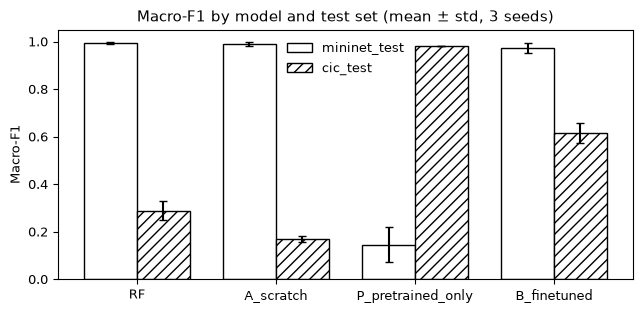

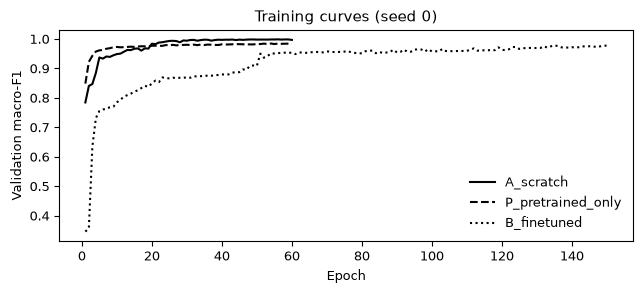

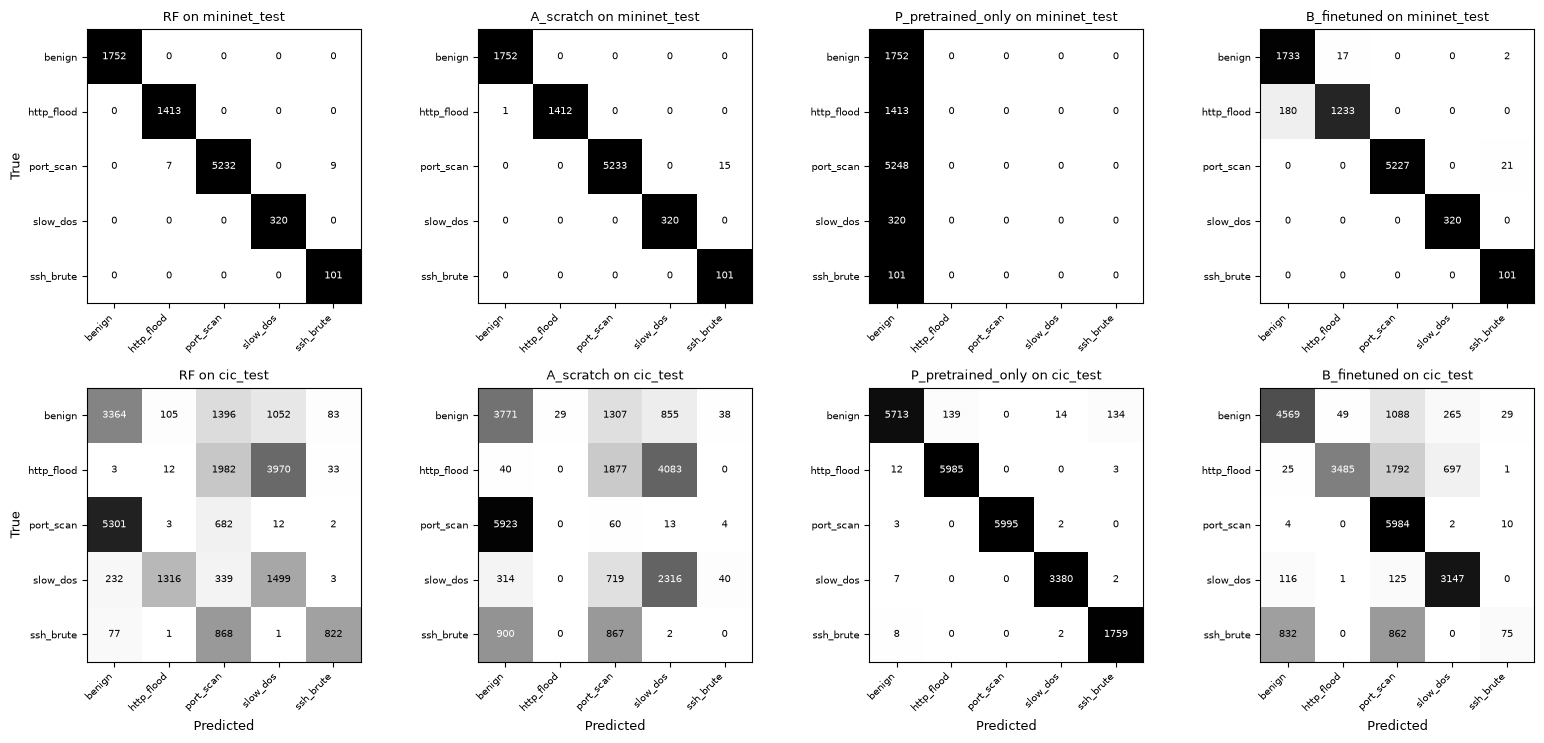

In [21]:
order = ["RF", "A_scratch", "P_pretrained_only", "B_finetuned"]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
w = 0.38
for k, (t, hatch) in enumerate([("mininet_test", ""), ("cic_test", "///")]):
    m = [summ.loc[(o, t), "macro_f1_mean"] for o in order]
    s = [summ.loc[(o, t), "macro_f1_std"] for o in order]
    ax.bar(np.arange(len(order)) + (k - 0.5) * w, m, w, yerr=s, capsize=3, color="white",
           edgecolor="black", hatch=hatch, label=t)
ax.set_xticks(range(len(order)), order); ax.set_ylabel("Macro-F1"); ax.set_ylim(0, 1.05)
ax.legend(frameon=False); ax.set_title("Macro-F1 by model and test set (mean ± std, 3 seeds)")
fig.tight_layout(); fig.savefig("results_2/macro_f1.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3))
for (name, h), ls in zip(curves.items(), ["-", "--", ":"]):
    ax.plot(range(1, len(h) + 1), h, ls, color="black", label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation macro-F1"); ax.legend(frameon=False)
ax.set_title("Training curves (seed 0)")
fig.tight_layout(); fig.savefig("results_2/training_curves.png", dpi=200); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for r, t in enumerate(["mininet_test", "cic_test"]):
    for c, name in enumerate(order):
        cm = cms[(name, t)]; ax = axes[r, c]
        norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(norm, cmap="Greys", vmin=0, vmax=1)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if norm[i, j] > 0.5 else "black")
        ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right", fontsize=7)
        ax.set_yticks(range(len(CLASSES)), CLASSES, fontsize=7)
        ax.set_title(f"{name} on {t}", fontsize=9)
        if c == 0: ax.set_ylabel("True")
        if r == 1: ax.set_xlabel("Predicted")
fig.tight_layout(); fig.savefig("results_2/confusion_matrices.png", dpi=200); plt.show()

## 8. Export the model for the live demo on Kali

The better of Model A and Model B on the Mininet test set is saved as plain numbers
(`models/detector.npz`: weights, scaler, feature list, classes). Kali runs it with
NumPy only, so no PyTorch is needed there. A check confirms the NumPy version gives
the same predictions as PyTorch.

In [22]:
cand = {n: summ.loc[(n, "mininet_test"), "macro_f1_mean"] for n in ["A_scratch", "B_finetuned"]}
best = max(cand, key=cand.get)
model, scaler = keep[SEEDS[0]][best]
lin = [m for m in model.modules() if isinstance(m, nn.Linear)]
arrs = {}
for i, l in enumerate(lin):
    arrs[f"W{i}"] = l.weight.detach().cpu().numpy().T
    arrs[f"b{i}"] = l.bias.detach().cpu().numpy()
np.savez("models/detector.npz", **arrs, n_layers=len(lin), mean=scaler.mean_, scale=scaler.scale_,
         features=np.array(feats), classes=np.array(CLASSES), name=np.array(best))

# check: NumPy forward pass == PyTorch
Xs = scaler.transform(TESTS["mininet_test"][0])
h = Xs
for i in range(len(lin)):
    h = h @ arrs[f"W{i}"] + arrs[f"b{i}"]
    if i < len(lin) - 1: h = np.maximum(h, 0)
same = (h.argmax(1) == predict(model, Xs)).mean()
print(f"Exported {best} (seed {SEEDS[0]}) -> models/detector.npz | NumPy vs PyTorch agreement: {same:.4f}")

Exported A_scratch (seed 0) -> models/detector.npz | NumPy vs PyTorch agreement: 1.0000
